Drive loading

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Cuda setup. In this case, cuda 12.9 is used. Please run this cell again after restarting session if asked.

In [ ]:

# ============================================================
# RUMC ULTRASOUND - COMPLETE CUDA SETUP
# Google Colab | NVIDIA Tesla T4 | Python 3.13 | CUDA 12.x
# ============================================================

import os
import sys
import glob
import ctypes
import subprocess
import importlib.metadata as md

print("=" * 60)
print("RUMC ULTRASOUND - CUDA ENVIRONMENT SETUP")
print("=" * 60)

# ============================================================
# STEP 1: CHECK AND INSTALL DEPENDENCIES
# ============================================================

print("\n========== CHECKING DEPENDENCIES ==========")

required_versions = {
    "cupy-cuda12x": "14.2.0",
    "onnxruntime-gpu": "1.26.0",
}

needs_install = False

for package, required_version in required_versions.items():
    try:
        installed_version = md.version(package)
        print(f"{package}: {installed_version}")

        if installed_version != required_version:
            needs_install = True

    except md.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")
        needs_install = True

# Detect conflicting CuPy installations
for package in ["cupy", "cupy-cuda13x"]:
    try:
        print(f"Conflicting package found: {package} {md.version(package)}")
        needs_install = True
    except md.PackageNotFoundError:
        pass

if needs_install:

    print("\n========== CLEANING CUPY INSTALLATIONS ==========")

    subprocess.run(
        [
            sys.executable, "-m", "pip", "uninstall", "-y",
            "cupy", "cupy-cuda12x", "cupy-cuda13x"
        ],
        check=False
    )

    print("\n========== INSTALLING DEPENDENCIES ==========")

    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-U",
        "cupy-cuda12x[ctk]==14.2.0",
        "onnxruntime-gpu[cuda,cudnn]==1.26.0",
        "numpy",
        "scipy",
        "scikit-image",
        "h5py",
        "matplotlib"
    ])

    print("\n" + "=" * 60)
    print("INSTALLATION COMPLETED")
    print("PLEASE RESTART THE COLAB RUNTIME.")
    print("After restarting, run this SAME setup cell again.")
    print("=" * 60)

else:
    print("\nRequired package versions are already installed.")

    # ========================================================
    # STEP 2: NVIDIA LIBRARY DIAGNOSTICS
    # ========================================================

    print("\n========== NVIDIA LIBRARY DIAGNOSTICS ==========")

    BASE = "/usr/local/lib/python3.13/dist-packages/nvidia"

    patterns = [
        f"{BASE}/cublas/lib/libcublas.so*",
        f"{BASE}/cuda_runtime/lib/*",
        f"{BASE}/nvjitlink/lib/*",
        f"{BASE}/cufft/lib/*",
    ]

    for pattern in patterns:
        matches = glob.glob(pattern)
        print("\n", pattern)

        for path in matches[:5]:
            print("FOUND:", path)

        if not matches:
            print("NOT FOUND")

    print("\nLD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH"))

    # ========================================================
    # STEP 3: PRELOAD CUDA SHARED LIBRARIES
    # IMPORTANT: BEFORE IMPORTING CUPY
    # ========================================================

    libraries = [
        f"{BASE}/nvjitlink/lib/libnvJitLink.so.12",
        f"{BASE}/cuda_runtime/lib/libcudart.so.12",
        f"{BASE}/cublas/lib/libcublasLt.so.12",
        f"{BASE}/cublas/lib/libcublas.so.12",
        f"{BASE}/cufft/lib/libcufft.so.11",
    ]

    loaded = []

    print("\n========== PRELOADING CUDA LIBRARIES ==========")

    for path in libraries:

        if not os.path.isfile(path):
            raise FileNotFoundError(
                f"Required CUDA library not found: {path}"
            )

        handle = ctypes.CDLL(
            path,
            mode=ctypes.RTLD_GLOBAL
        )

        loaded.append(handle)

        print("LOADED:", os.path.basename(path))

    # ========================================================
    # STEP 4: IMPORT CUDA PROCESSING LIBRARIES
    # ========================================================

    print("\n========== IMPORTING CUDA MODULES ==========")

    import cupy as cp
    import onnxruntime as ort
    from cupyx.scipy.signal import hilbert

    print("CuPy:", cp.__version__)
    print("ONNX Runtime:", ort.__version__)

    # ========================================================
    # STEP 5: NVIDIA PACKAGE VERSIONS
    # ========================================================

    print("\n========== NVIDIA PACKAGE VERSIONS ==========")

    for package in [
        "nvidia-cublas-cu12",
        "nvidia-cuda-runtime-cu12",
        "nvidia-cufft-cu12",
        "nvidia-nvjitlink-cu12",
    ]:
        try:
            print(package, md.version(package))
        except Exception as e:
            print(package, "ERROR:", e)

    # ========================================================
    # STEP 6: VERIFY CUDA PROVIDERS
    # ========================================================

    print("\n========== ONNX RUNTIME PROVIDERS ==========")

    providers = ort.get_available_providers()

    print("Available providers:", providers)

    if "CUDAExecutionProvider" not in providers:
        raise RuntimeError(
            "CUDAExecutionProvider is not available."
        )

    # ========================================================
    # STEP 7: GPU CALCULATION TEST
    # ========================================================

    print("\n========== GPU CALCULATION TEST ==========")

    x = cp.arange(1000, dtype=cp.float32)

    gpu_sum = float(cp.sum(x).get())

    print("GPU calculation:", gpu_sum)
    print("GPU device count:", cp.cuda.runtime.getDeviceCount())

    # ========================================================
    # STEP 8: GPU FFT TEST
    # ========================================================

    print("\n========== GPU FFT TEST ==========")

    fft_result = cp.fft.fft(x)

    cp.cuda.Stream.null.synchronize()

    print("GPU FFT: SUCCESS")

    # ========================================================
    # STEP 9: GPU HILBERT TEST
    # ========================================================

    print("\n========== GPU HILBERT TEST ==========")

    signal = cp.sin(cp.linspace(0, 10, 1024))

    envelope = cp.abs(hilbert(signal))

    cp.cuda.Stream.null.synchronize()

    print("GPU Hilbert: SUCCESS")
    print("Envelope shape:", envelope.shape)

    # ========================================================
    # STEP 10: FINAL STATUS
    # ========================================================

    print("\n" + "=" * 60)
    print("CUDA INITIALIZATION SUCCESSFUL")
    print("=" * 60)

    print("GPU:", cp.cuda.runtime.getDeviceProperties(0)["name"])
    print("CuPy:", cp.__version__)
    print("ONNX Runtime:", ort.__version__)
    print("CUDA Execution Provider: AVAILABLE")
    print("GPU Calculation: SUCCESS")
    print("GPU FFT: SUCCESS")
    print("GPU Hilbert: SUCCESS")

    print("\nCUDA VERIFICATION COMPLETE")
    print("=" * 60)


RUMC ULTRASOUND - CUDA ENVIRONMENT SETUP

========== CHECKING DEPENDENCIES ==========
cupy-cuda12x: 14.2.0
onnxruntime-gpu: 1.26.0

Required package versions are already installed.

========== NVIDIA LIBRARY DIAGNOSTICS ==========

 /usr/local/lib/python3.13/dist-packages/nvidia/cublas/lib/libcublas.so*
FOUND: /usr/local/lib/python3.13/dist-packages/nvidia/cublas/lib/libcublas.so.12

 /usr/local/lib/python3.13/dist-packages/nvidia/cuda_runtime/lib/*
FOUND: /usr/local/lib/python3.13/dist-packages/nvidia/cuda_runtime/lib/libcudart_static.a
FOUND: /usr/local/lib/python3.13/dist-packages/nvidia/cuda_runtime/lib/libcudart.so.12
FOUND: /usr/local/lib/python3.13/dist-packages/nvidia/cuda_runtime/lib/libcudadevrt.a
FOUND: /usr/local/lib/python3.13/dist-packages/nvidia/cuda_runtime/lib/libculibos.a

 /usr/local/lib/python3.13/dist-packages/nvidia/nvjitlink/lib/*
FOUND: /usr/local/lib/python3.13/dist-packages/nvidia/nvjitlink/lib/libnvJitLink.so.12

 /usr/local/lib/python3.13/dist-packages/nvidi

/usr/local/lib/python3.13/dist-packages/cupyx/jit/_interface.py:247: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


CuPy: 14.2.0
ONNX Runtime: 1.26.0

========== NVIDIA PACKAGE VERSIONS ==========
nvidia-cublas-cu12 12.9.2.10
nvidia-cuda-runtime-cu12 12.9.79
nvidia-cufft-cu12 11.4.1.4
nvidia-nvjitlink-cu12 12.9.86

========== ONNX RUNTIME PROVIDERS ==========
Available providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']

========== GPU CALCULATION TEST ==========
GPU calculation: 499500.0
GPU device count: 1

========== GPU FFT TEST ==========
GPU FFT: SUCCESS

========== GPU HILBERT TEST ==========
GPU Hilbert: SUCCESS
Envelope shape: (1024,)

CUDA INITIALIZATION SUCCESSFUL
GPU: b'Tesla T4'
CuPy: 14.2.0
ONNX Runtime: 1.26.0
CUDA Execution Provider: AVAILABLE
GPU Calculation: SUCCESS
GPU FFT: SUCCESS
GPU Hilbert: SUCCESS

CUDA VERIFICATION COMPLETE


Cuda Code

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
All required files found.

========== CUDA INITIALIZATION ==========
GPU: Tesla T4
CuPy version: 14.2.0
CUDA test successful.

CUDA processing modules imported.

========== HEADER LOADING ==========
Header variables: ['#refs#', 'USHEADER']
Header loaded successfully.
Transmission angles: [-16.         -15.56756757 -15.13513514 -14.7027027  -14.27027027
 -13.83783784 -13.40540541 -12.97297297 -12.54054054 -12.10810811
 -11.67567568 -11.24324324 -10.81081081 -10.37837838  -9.94594595
  -9.51351351  -9.08108108  -8.64864865  -8.21621622  -7.78378378
  -7.35135135  -6.91891892  -6.48648649  -6.05405405  -5.62162162
  -5.18918919  -4.75675676  -4.32432432  -3.89189189  -3.45945946
  -3.02702703  -2.59459459  -2.16216216  -1.72972973  -1.2972973
  -0.86486486  -0.43243243   0.           0.43243243   0.86486486
   1.2972973    1.72972973   2.16216216   2.59459459   

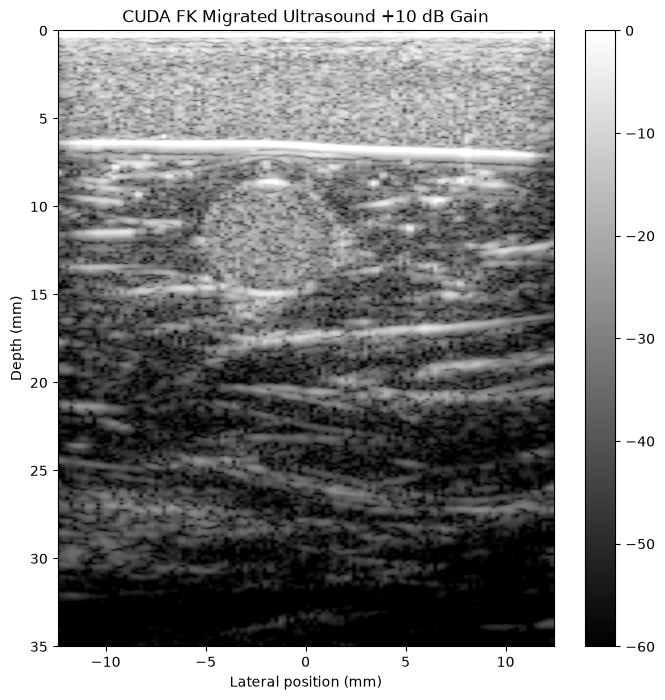


========== CUDA IMAGE ENHANCEMENT ==========
CUDA enhancement completed.
Enhanced image dimensions: (2848, 128)
Enhanced image dtype: float32

Displaying enhanced B-mode image...


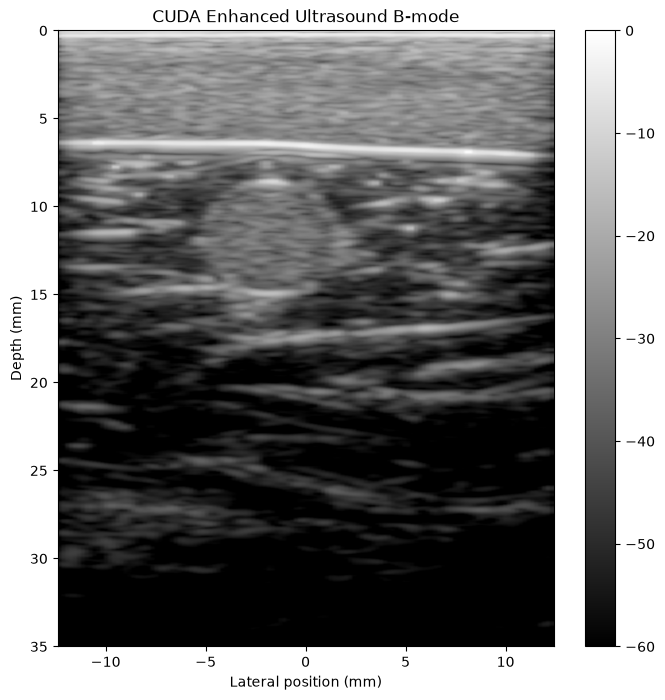


========== CNN INPUT PREPARATION ==========
CNN input prepared.
CNN input shape: (1, 1, 2848, 128)
CNN input dtype: float32
CNN execution provider: CUDAExecutionProvider

========== CNN CLASSIFICATION ==========
Classification completed.


       RUMC ULTRASOUND CLASSIFICATION       

Predicted Class: Hyper_lesion

Class Confidence Scores:
  No_lesion      : 15.81 %
  Hypo_lesion    : 10.99 %
  Hyper_lesion   : 73.20 %



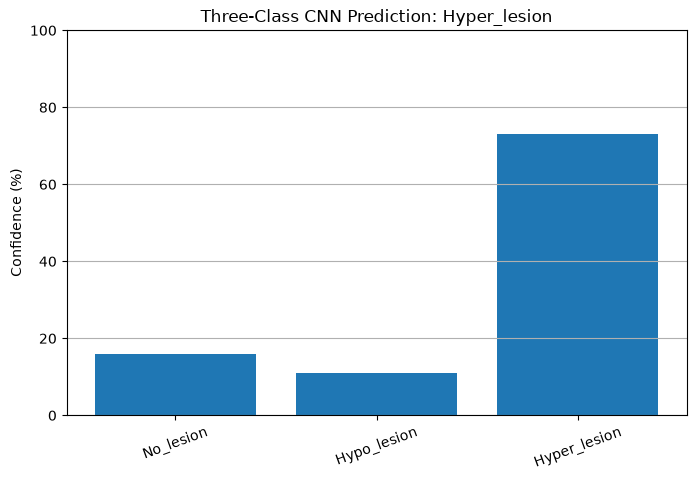


========== PIPELINE COMPLETE ==========
Ultrasound data loading: SUCCESS
CUDA preprocessing: SUCCESS
CUDA FK migration: SUCCESS
CUDA Hilbert envelope: SUCCESS
CUDA normalization and gain: SUCCESS
CUDA image enhancement: SUCCESS
ONNX CNN classification: SUCCESS

GPU: Tesla T4

Final Prediction: Hyper_lesion

Final GPU image variable: enhanced_img_gpu
Final CPU image variable: cnnInput
CNN confidence scores variable: scores



In [ ]:

# ============================================================
# FINAL RUMC ULTRASOUND IMPLEMENTATION
# CUDA-OPTIMIZED GOOGLE COLAB VERSION
#
# Hardware: NVIDIA Tesla T4
#
# Pipeline:
# Raw RF Data
#     -> CUDA Preprocessing
#     -> CUDA FK Migration
#     -> CUDA Hilbert Envelope
#     -> CUDA Normalization
#     -> CUDA +10 dB Gain
#     -> CUDA Image Enhancement
#     -> ONNX CUDA CNN Classification
#     -> B-mode Display
#
# Classes:
#   1. No_lesion
#   2. Hypo_lesion
#   3. Hyper_lesion
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import sys
import importlib
import h5py
import numpy as np
import cupy as cp
import matplotlib.pyplot as plt
import onnxruntime as ort

from cupyx.scipy.signal import hilbert
from google.colab import drive


# ============================================================
# 2. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount('/content/drive')


# ============================================================
# 3. FILE CONFIGURATION
# ============================================================

DATA_PATH = (
    "/content/drive/MyDrive/Dataset/Hyper_lesion/USDATA_20210624113025661.mat"
)

HEADER_PATH = (
    "/content/drive/MyDrive/"
    "USHEADER_20210624112712.mat"
)

ONNX_PATH = (
    "/content/drive/MyDrive/"
    "RUMC_ThreeClass_CNN.onnx"
)

sys.path.append('/content/drive/MyDrive')


# ============================================================
# 4. CHECK REQUIRED FILES
# ============================================================

for path in [DATA_PATH, HEADER_PATH, ONNX_PATH]:

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("All required files found.")


# ============================================================
# 5. VERIFY CUDA GPU
# ============================================================

print("\n========== CUDA INITIALIZATION ==========")

if cp.cuda.runtime.getDeviceCount() == 0:
    raise RuntimeError("No CUDA GPU detected.")

gpu_name = cp.cuda.runtime.getDeviceProperties(0)["name"]

if isinstance(gpu_name, bytes):
    gpu_name = gpu_name.decode()

print("GPU:", gpu_name)
print("CuPy version:", cp.__version__)

# Test GPU computation
test_gpu = cp.arange(10, dtype=cp.float64) ** 2

cp.cuda.Stream.null.synchronize()

print("CUDA test successful.")


# ============================================================
# 6. IMPORT CUDA PROCESSING FUNCTIONS
# ============================================================

import preprocessing as preprocessing_module
import fkmig as fkmig_module
import enhancement2 as enhancement_module

# Reload modules to use the latest saved versions
importlib.reload(preprocessing_module)
importlib.reload(fkmig_module)
importlib.reload(enhancement_module)

preprocessing = preprocessing_module.preprocessing
fkmig = fkmig_module.fkmig
enhancement2 = enhancement_module.enhancement2

print("\nCUDA processing modules imported.")


# ============================================================
# 7. MATLAB V7.3 DATA LOADER
# ============================================================

def matlab_array(dataset):

    arr = np.array(dataset)

    if arr.ndim > 1:

        arr = np.transpose(
            arr,
            axes=tuple(range(arr.ndim - 1, -1, -1))
        )

    return arr


# ============================================================
# 8. LOAD ULTRASOUND HEADER
# ============================================================

print("\n========== HEADER LOADING ==========")

with h5py.File(HEADER_PATH, "r") as f:

    print("Header variables:", list(f.keys()))

    header_group = f["USHEADER"]

    angle_dataset = header_group["xmitAngles"]

    # Handle MATLAB v7.3 object references
    if h5py.check_dtype(ref=angle_dataset.dtype) is not None:

        refs = angle_dataset[()].flatten()

        valid_refs = [ref for ref in refs if ref]

        if not valid_refs:
            raise ValueError(
                "No valid xmitAngles reference found."
            )

        angle_dataset = f[valid_refs[0]]

    tx_angles = matlab_array(
        angle_dataset
    ).squeeze()

tx_angles = np.asarray(
    tx_angles,
    dtype=np.float64
).flatten()

USHEADER = {
    "xmitAngles": tx_angles
}

print("Header loaded successfully.")
print("Transmission angles:", tx_angles)


# ============================================================
# 9. RECONSTRUCTION PARAMETERS
# ============================================================

param = {}

param["x"] = np.linspace(
    -0.0125,
    0.0125,
    128
)

param["y"] = np.linspace(
    0,
    0.0725,
    500
)

param["fs"] = 31250000
param["c"] = 1540
param["p"] = 0

param["TXangle"] = np.deg2rad(tx_angles)

param["pitch"] = 1.953000000000000e-04

param["passband"] = [0.3, 0.7]

param["ncol"] = 128

param["t0"] = 0

print("Reconstruction parameters initialized.")


# ============================================================
# 10. LOAD ONNX CNN WITH CUDA PROVIDER
# ============================================================

print("\n========== CNN MODEL LOADING ==========")

available_providers = ort.get_available_providers()

print("Available ONNX providers:", available_providers)

if "CUDAExecutionProvider" not in available_providers:
    raise RuntimeError(
        "ONNX Runtime CUDAExecutionProvider is unavailable. "
        "Install a compatible onnxruntime-gpu package."
    )

session = ort.InferenceSession(
    ONNX_PATH,
    providers=[
        "CUDAExecutionProvider",
        "CPUExecutionProvider"
    ]
)

print(
    "Active ONNX providers:",
    session.get_providers()
)

if "CUDAExecutionProvider" not in session.get_providers():
    raise RuntimeError(
        "ONNX Runtime failed to activate CUDAExecutionProvider."
    )

input_info = session.get_inputs()[0]

output_info = session.get_outputs()

print("ONNX model loaded successfully.")

print("CNN input name:", input_info.name)
print("CNN input shape:", input_info.shape)
print("CNN input type:", input_info.type)

print("\nCNN output information:")

for output in output_info:

    print(
        output.name,
        output.shape,
        output.type
    )


# ============================================================
# 11. LOAD RAW ULTRASOUND DATA
# ============================================================

print("\n========== ULTRASOUND DATA LOADING ==========")

with h5py.File(DATA_PATH, "r") as f:

    print("Input variables:", list(f.keys()))

    if "USDATA" not in f:
        raise KeyError(
            "USDATA variable not found in input MAT file."
        )

    sig = matlab_array(f["USDATA"])

sig = np.squeeze(sig)

print("Raw RF data loaded.")
print("Raw RF dimensions:", sig.shape)
print("Raw RF dtype:", sig.dtype)


# ============================================================
# 12. CUDA PREPROCESSING
# ============================================================

print("\n========== CUDA PREPROCESSING ==========")

useZeroDegreeOnly = False

if useZeroDegreeOnly:

    sig_gpu, param = preprocessing(
        sig,
        USHEADER,
        param,
        1
    )

else:

    sig_gpu, param = preprocessing(
        sig,
        USHEADER,
        param
    )

cp.cuda.Stream.null.synchronize()

if not isinstance(sig_gpu, cp.ndarray):
    raise TypeError(
        "Preprocessing did not return a CuPy GPU array."
    )

print("CUDA preprocessing completed.")
print("Preprocessed dimensions:", sig_gpu.shape)
print("Preprocessed dtype:", sig_gpu.dtype)


# ============================================================
# 13. CUDA FK MIGRATION
# ============================================================

print("\n========== CUDA FK MIGRATION ==========")

migSIG_gpu, param = fkmig(
    sig_gpu,
    param
)

cp.cuda.Stream.null.synchronize()

if not isinstance(migSIG_gpu, cp.ndarray):
    raise TypeError(
        "FK migration did not return a CuPy GPU array."
    )

if (
    migSIG_gpu.size == 0
    or not bool(cp.all(cp.isfinite(migSIG_gpu)).get())
):
    raise ValueError(
        "Invalid FK migration output."
    )

print("CUDA FK migration completed.")
print("Migrated dimensions:", migSIG_gpu.shape)
print("Migrated dtype:", migSIG_gpu.dtype)


# ============================================================
# 14. CUDA HILBERT ENVELOPE DETECTION
# ============================================================

print("\n========== CUDA ENVELOPE DETECTION ==========")

# MATLAB:
# env = abs(hilbert(migSIG));

env_gpu = cp.abs(
    hilbert(
        migSIG_gpu,
        axis=0
    )
)

cp.cuda.Stream.null.synchronize()

if (
    env_gpu.size == 0
    or not bool(cp.all(cp.isfinite(env_gpu)).get())
):
    raise ValueError(
        "Invalid envelope output."
    )

print("CUDA envelope detection completed.")
print("Envelope dimensions:", env_gpu.shape)


# ============================================================
# 15. CUDA ENVELOPE NORMALIZATION
# ============================================================

print("\n========== CUDA NORMALIZATION ==========")

eps_matlab = np.finfo(np.float64).eps

env_max = cp.max(env_gpu)

env_gpu = env_gpu / (
    env_max + eps_matlab
)

print("CUDA envelope normalization completed.")


# ============================================================
# 16. CUDA +10 dB GAIN
# ============================================================

print("\n========== CUDA GAIN ==========")

gain_dB = 10

gain = 10 ** (gain_dB / 20)

env_enhanced_gpu = env_gpu * gain

print(
    f"Applied uniform gain: +{gain_dB:.1f} dB"
)


# ============================================================
# 17. CUDA LOG COMPRESSION
# ============================================================

print("\n========== CUDA LOG COMPRESSION ==========")

env_dB_gpu = 20.0 * cp.log10(
    env_enhanced_gpu + eps_matlab
)

cp.cuda.Stream.null.synchronize()

print("CUDA log compression completed.")


# ============================================================
# 18. VERIFY FK IMAGE COORDINATES
# ============================================================

# Convert only small coordinate arrays to CPU.
# The ultrasound image remains on GPU.

def to_numpy(arr):

    if isinstance(arr, cp.ndarray):
        return cp.asnumpy(arr)

    return np.asarray(arr)


x_coordinates = np.asarray(
    to_numpy(param["x"])
).squeeze()

if x_coordinates.size != env_dB_gpu.shape[1]:
    raise ValueError(
        "Lateral coordinate size does not match migrated image."
    )

if (
    "z" in param
    and np.asarray(to_numpy(param["z"])).size
    == env_dB_gpu.shape[0]
):

    depthCoordinates = np.asarray(
        to_numpy(param["z"])
    ).squeeze()

elif (
    "y" in param
    and np.asarray(to_numpy(param["y"])).size
    == env_dB_gpu.shape[0]
):

    depthCoordinates = np.asarray(
        to_numpy(param["y"])
    ).squeeze()

else:

    raise ValueError(
        "No matching depth coordinate for migrated image."
    )


# ============================================================
# 19. DISPLAY FK MIGRATED IMAGE
# ============================================================

print("\nDisplaying FK migrated image...")

# Transfer image to CPU only for Matplotlib.
env_dB_display = cp.asnumpy(env_dB_gpu)

plt.figure(figsize=(8, 8))

plt.imshow(
    env_dB_display,
    extent=[
        x_coordinates[0] * 1000,
        x_coordinates[-1] * 1000,
        depthCoordinates[-1] * 1000,
        depthCoordinates[0] * 1000
    ],
    aspect="auto",
    cmap="gray",
    vmin=-60,
    vmax=0,
    origin="upper"
)

plt.ylim(35, 0)

plt.colorbar()

plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")

plt.title(
    "CUDA FK Migrated Ultrasound +10 dB Gain"
)

plt.show()

del env_dB_display


# ============================================================
# 20. CUDA IMAGE ENHANCEMENT
# ============================================================

print("\n========== CUDA IMAGE ENHANCEMENT ==========")

enhanced_img_gpu = enhancement2(
    env_enhanced_gpu
)

enhanced_img_gpu = cp.squeeze(
    enhanced_img_gpu
)

cp.cuda.Stream.null.synchronize()

if (
    enhanced_img_gpu.size == 0
    or enhanced_img_gpu.ndim != 2
    or not bool(
        cp.all(cp.isfinite(enhanced_img_gpu)).get()
    )
):

    raise ValueError(
        "Invalid output from enhancement2."
    )

# MATLAB:
# enhanced_img = single(enhanced_img);

enhanced_img_gpu = enhanced_img_gpu.astype(
    cp.float32
)

print("CUDA enhancement completed.")
print("Enhanced image dimensions:", enhanced_img_gpu.shape)
print("Enhanced image dtype:", enhanced_img_gpu.dtype)


# ============================================================
# 21. VERIFY ENHANCED IMAGE COORDINATES
# ============================================================

if enhanced_img_gpu.shape[1] != x_coordinates.size:
    raise ValueError(
        "Enhanced image width does not match lateral coordinates."
    )

if (
    "y" in param
    and np.asarray(to_numpy(param["y"])).size
    == enhanced_img_gpu.shape[0]
):

    enhancedDepth = np.asarray(
        to_numpy(param["y"])
    ).squeeze()

elif (
    "z" in param
    and np.asarray(to_numpy(param["z"])).size
    == enhanced_img_gpu.shape[0]
):

    enhancedDepth = np.asarray(
        to_numpy(param["z"])
    ).squeeze()

else:

    raise ValueError(
        "No matching depth coordinate for enhanced image."
    )


# ============================================================
# 22. DISPLAY ENHANCED B-MODE IMAGE
# ============================================================

print("\nDisplaying enhanced B-mode image...")

# Transfer to CPU only for display.

enhanced_img_display = cp.asnumpy(
    enhanced_img_gpu
)

plt.figure(figsize=(8, 8))

plt.imshow(
    enhanced_img_display,
    extent=[
        x_coordinates[0] * 1000,
        x_coordinates[-1] * 1000,
        enhancedDepth[-1] * 1000,
        enhancedDepth[0] * 1000
    ],
    aspect="auto",
    cmap="gray",
    vmin=-60,
    vmax=0,
    origin="upper"
)

plt.ylim(35, 0)

plt.colorbar()

plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")

plt.title(
    "CUDA Enhanced Ultrasound B-mode"
)

plt.show()

del enhanced_img_display


# ============================================================
# 23. CNN INPUT PREPARATION
# ============================================================

print("\n========== CNN INPUT PREPARATION ==========")

# Keep GPU version for subsequent GPU processing.
# Transfer to CPU for standard ONNX Runtime input.

cnn_img = enhanced_img_gpu

model_shape = input_info.shape

if len(model_shape) != 4:

    raise ValueError(
        f"Expected a 4D CNN input, got: {model_shape}"
    )

# Determine NCHW or NHWC layout.

if (
    isinstance(model_shape[1], int)
    and model_shape[1] == 1
):

    cnn_input_gpu = cnn_img[
        cp.newaxis,
        cp.newaxis,
        :,
        :
    ]

elif (
    isinstance(model_shape[3], int)
    and model_shape[3] == 1
):

    cnn_input_gpu = cnn_img[
        cp.newaxis,
        :,
        :,
        cp.newaxis
    ]

else:

    raise ValueError(
        "Could not determine CNN channel layout. "
        f"Model input shape: {model_shape}"
    )


# Validate static input dimensions.

for actual, expected in zip(
    cnn_input_gpu.shape,
    model_shape
):

    if isinstance(expected, int) and actual != expected:

        raise ValueError(
            f"CNN input mismatch. "
            f"Model expects {model_shape}, "
            f"but generated {cnn_input_gpu.shape}."
        )


# Convert to contiguous float32 GPU array.

cnn_input_gpu = cp.ascontiguousarray(
    cnn_input_gpu,
    dtype=cp.float32
)

# ONNX Runtime standard input uses NumPy.
# This is the GPU-to-CPU transfer before inference.

cnnInput = cp.asnumpy(
    cnn_input_gpu
)

cnnInput = np.ascontiguousarray(
    cnnInput,
    dtype=np.float32
)

print("CNN input prepared.")
print("CNN input shape:", cnnInput.shape)
print("CNN input dtype:", cnnInput.dtype)
print("CNN execution provider:", session.get_providers()[0])


# ============================================================
# 24. THREE-CLASS ONNX CNN CLASSIFICATION
# ============================================================

print("\n========== CNN CLASSIFICATION ==========")

outputs = session.run(
    None,
    {
        input_info.name: cnnInput
    }
)

# Select output containing three class scores.

class_output = None

for out in outputs:

    arr = np.asarray(out)

    if arr.size == 3:

        class_output = arr.reshape(-1)

        break

if class_output is None:

    raise ValueError(
        "Could not identify a three-class output. "
        f"Output shapes: "
        f"{[np.asarray(o).shape for o in outputs]}"
    )

if not np.all(np.isfinite(class_output)):

    raise ValueError(
        "CNN returned non-finite output scores."
    )


# ============================================================
# 25. CONVERT OUTPUT TO PROBABILITIES
# ============================================================

if (
    np.all(class_output >= 0)
    and np.all(class_output <= 1)
    and np.isclose(
        np.sum(class_output),
        1.0,
        atol=1e-3
    )
):

    scores = class_output

else:

    shifted = class_output - np.max(class_output)

    exp_scores = np.exp(shifted)

    scores = exp_scores / np.sum(exp_scores)


# ============================================================
# 26. CLASS LABELS
# ============================================================

# Confirm this order against original MATLAB:
# net.Layers(end).Classes

classNames = [
    "No_lesion",
    "Hypo_lesion",
    "Hyper_lesion"
]

predicted_index = int(
    np.argmax(scores)
)

resultLabel = classNames[predicted_index]

print("Classification completed.")


# ============================================================
# 27. DISPLAY CLASSIFICATION RESULTS
# ============================================================

print("\n")
print("============================================")
print("       RUMC ULTRASOUND CLASSIFICATION       ")
print("============================================")

print("\nPredicted Class:", resultLabel)

print("\nClass Confidence Scores:")

for name, score in zip(classNames, scores):

    print(
        f"  {name:<15}: {score * 100:.2f} %"
    )

print("\n============================================")


# ============================================================
# 28. DISPLAY CNN PREDICTION GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    classNames,
    scores * 100
)

plt.ylabel("Confidence (%)")

plt.ylim(0, 100)

plt.title(
    f"Three-Class CNN Prediction: {resultLabel}"
)

plt.xticks(rotation=20)

plt.grid(axis="y")

plt.show()


# ============================================================
# 29. FINAL COMPLETION
# ============================================================

print("\n========== PIPELINE COMPLETE ==========")

print("Ultrasound data loading: SUCCESS")
print("CUDA preprocessing: SUCCESS")
print("CUDA FK migration: SUCCESS")
print("CUDA Hilbert envelope: SUCCESS")
print("CUDA normalization and gain: SUCCESS")
print("CUDA image enhancement: SUCCESS")
print("ONNX CNN classification: SUCCESS")

print("\nGPU:", gpu_name)

print("\nFinal Prediction:", resultLabel)

print("\nFinal GPU image variable: enhanced_img_gpu")
print("Final CPU image variable: cnnInput")
print("CNN confidence scores variable: scores")

print("\n============================================")


Metrics and time calculation

In [ ]:

# ============================================================
# FINAL RUMC ULTRASOUND IMPLEMENTATION
# CUDA-OPTIMIZED GOOGLE COLAB VERSION
#
# Hardware: NVIDIA Tesla T4
#
# Pipeline:
# Raw RF Data
#     -> CUDA Preprocessing
#     -> CUDA FK Migration
#     -> CUDA Hilbert Envelope
#     -> CUDA Normalization
#     -> CUDA +10 dB Gain
#     -> CUDA Image Enhancement
#     -> ONNX CUDA CNN Classification
#     -> B-mode Display
#
# Classes:
#   1. No_lesion
#   2. Hypo_lesion
#   3. Hyper_lesion
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import sys
import builtins
import time
import warnings
import importlib
import h5py
import numpy as np
import cupy as cp
import matplotlib.pyplot as plt
import onnxruntime as ort

from cupyx.scipy.signal import hilbert
from google.colab import drive


# ============================================================
# 2. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount('/content/drive')

# Suppress pipeline text output; final metrics are printed at the end.
_original_print = builtins.print
builtins.print = lambda *args, **kwargs: None
warnings.filterwarnings("ignore")
plt.ioff()



# ============================================================
# 3. FILE CONFIGURATION
# ============================================================

DATA_PATH = (
    "/content/drive/MyDrive/Dataset/Hyper_lesion/USDATA_20210624113025661.mat"
)

HEADER_PATH = (
    "/content/drive/MyDrive/"
    "USHEADER_20210624112712.mat"
)

ONNX_PATH = (
    "/content/drive/MyDrive/"
    "RUMC_ThreeClass_CNN.onnx"
)

sys.path.append('/content/drive/MyDrive')


# ============================================================
# 4. CHECK REQUIRED FILES
# ============================================================

for path in [DATA_PATH, HEADER_PATH, ONNX_PATH]:

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

print("All required files found.")


# ============================================================
# 5. VERIFY CUDA GPU
# ============================================================

print("\n========== CUDA INITIALIZATION ==========")

if cp.cuda.runtime.getDeviceCount() == 0:
    raise RuntimeError("No CUDA GPU detected.")

gpu_name = cp.cuda.runtime.getDeviceProperties(0)["name"]

if isinstance(gpu_name, bytes):
    gpu_name = gpu_name.decode()

print("GPU:", gpu_name)
print("CuPy version:", cp.__version__)

# Test GPU computation
test_gpu = cp.arange(10, dtype=cp.float64) ** 2

cp.cuda.Stream.null.synchronize()

print("CUDA test successful.")


# ============================================================
# 6. IMPORT CUDA PROCESSING FUNCTIONS
# ============================================================

import preprocessing as preprocessing_module
import fkmig as fkmig_module
import enhancement2 as enhancement_module

# Reload modules to use the latest saved versions
importlib.reload(preprocessing_module)
importlib.reload(fkmig_module)
importlib.reload(enhancement_module)

preprocessing = preprocessing_module.preprocessing
fkmig = fkmig_module.fkmig
enhancement2 = enhancement_module.enhancement2

print("\nCUDA processing modules imported.")


# ============================================================
# 7. MATLAB V7.3 DATA LOADER
# ============================================================

def matlab_array(dataset):

    arr = np.array(dataset)

    if arr.ndim > 1:

        arr = np.transpose(
            arr,
            axes=tuple(range(arr.ndim - 1, -1, -1))
        )

    return arr


# ============================================================
# 8. LOAD ULTRASOUND HEADER
# ============================================================

print("\n========== HEADER LOADING ==========")

with h5py.File(HEADER_PATH, "r") as f:

    print("Header variables:", list(f.keys()))

    header_group = f["USHEADER"]

    angle_dataset = header_group["xmitAngles"]

    # Handle MATLAB v7.3 object references
    if h5py.check_dtype(ref=angle_dataset.dtype) is not None:

        refs = angle_dataset[()].flatten()

        valid_refs = [ref for ref in refs if ref]

        if not valid_refs:
            raise ValueError(
                "No valid xmitAngles reference found."
            )

        angle_dataset = f[valid_refs[0]]

    tx_angles = matlab_array(
        angle_dataset
    ).squeeze()

tx_angles = np.asarray(
    tx_angles,
    dtype=np.float64
).flatten()

USHEADER = {
    "xmitAngles": tx_angles
}

print("Header loaded successfully.")
print("Transmission angles:", tx_angles)


# ============================================================
# 9. RECONSTRUCTION PARAMETERS
# ============================================================

param = {}

param["x"] = np.linspace(
    -0.0125,
    0.0125,
    128
)

param["y"] = np.linspace(
    0,
    0.0725,
    500
)

param["fs"] = 31250000
param["c"] = 1540
param["p"] = 0

param["TXangle"] = np.deg2rad(tx_angles)

param["pitch"] = 1.953000000000000e-04

param["passband"] = [0.3, 0.7]

param["ncol"] = 128

param["t0"] = 0

print("Reconstruction parameters initialized.")


# ============================================================
# 10. LOAD ONNX CNN WITH CUDA PROVIDER
# ============================================================

print("\n========== CNN MODEL LOADING ==========")

available_providers = ort.get_available_providers()

print("Available ONNX providers:", available_providers)

if "CUDAExecutionProvider" not in available_providers:
    raise RuntimeError(
        "ONNX Runtime CUDAExecutionProvider is unavailable. "
        "Install a compatible onnxruntime-gpu package."
    )

session = ort.InferenceSession(
    ONNX_PATH,
    providers=[
        "CUDAExecutionProvider",
        "CPUExecutionProvider"
    ]
)

print(
    "Active ONNX providers:",
    session.get_providers()
)

if "CUDAExecutionProvider" not in session.get_providers():
    raise RuntimeError(
        "ONNX Runtime failed to activate CUDAExecutionProvider."
    )

input_info = session.get_inputs()[0]

output_info = session.get_outputs()

print("ONNX model loaded successfully.")

print("CNN input name:", input_info.name)
print("CNN input shape:", input_info.shape)
print("CNN input type:", input_info.type)

print("\nCNN output information:")

for output in output_info:

    print(
        output.name,
        output.shape,
        output.type
    )


# ============================================================
# 11. LOAD RAW ULTRASOUND DATA
# ============================================================

print("\n========== ULTRASOUND DATA LOADING ==========")

with h5py.File(DATA_PATH, "r") as f:

    print("Input variables:", list(f.keys()))

    if "USDATA" not in f:
        raise KeyError(
            "USDATA variable not found in input MAT file."
        )

    sig = matlab_array(f["USDATA"])

sig = np.squeeze(sig)

print("Raw RF data loaded.")
print("Raw RF dimensions:", sig.shape)
print("Raw RF dtype:", sig.dtype)


# ============================================================
# 12. CUDA PREPROCESSING
# ============================================================

print("\n========== CUDA PREPROCESSING ==========")

# Benchmark starts: preprocessing through CNN classification.
cp.cuda.Stream.null.synchronize()
processing_start = time.perf_counter()

useZeroDegreeOnly = False

if useZeroDegreeOnly:

    sig_gpu, param = preprocessing(
        sig,
        USHEADER,
        param,
        1
    )

else:

    sig_gpu, param = preprocessing(
        sig,
        USHEADER,
        param
    )

cp.cuda.Stream.null.synchronize()

if not isinstance(sig_gpu, cp.ndarray):
    raise TypeError(
        "Preprocessing did not return a CuPy GPU array."
    )

print("CUDA preprocessing completed.")
print("Preprocessed dimensions:", sig_gpu.shape)
print("Preprocessed dtype:", sig_gpu.dtype)


# ============================================================
# 13. CUDA FK MIGRATION
# ============================================================

print("\n========== CUDA FK MIGRATION ==========")

migSIG_gpu, param = fkmig(
    sig_gpu,
    param
)

cp.cuda.Stream.null.synchronize()

if not isinstance(migSIG_gpu, cp.ndarray):
    raise TypeError(
        "FK migration did not return a CuPy GPU array."
    )

if (
    migSIG_gpu.size == 0
    or not bool(cp.all(cp.isfinite(migSIG_gpu)).get())
):
    raise ValueError(
        "Invalid FK migration output."
    )

print("CUDA FK migration completed.")
print("Migrated dimensions:", migSIG_gpu.shape)
print("Migrated dtype:", migSIG_gpu.dtype)


# ============================================================
# 14. CUDA HILBERT ENVELOPE DETECTION
# ============================================================

print("\n========== CUDA ENVELOPE DETECTION ==========")

# MATLAB:
# env = abs(hilbert(migSIG));

env_gpu = cp.abs(
    hilbert(
        migSIG_gpu,
        axis=0
    )
)

cp.cuda.Stream.null.synchronize()

if (
    env_gpu.size == 0
    or not bool(cp.all(cp.isfinite(env_gpu)).get())
):
    raise ValueError(
        "Invalid envelope output."
    )

print("CUDA envelope detection completed.")
print("Envelope dimensions:", env_gpu.shape)


# ============================================================
# 15. CUDA ENVELOPE NORMALIZATION
# ============================================================

print("\n========== CUDA NORMALIZATION ==========")

eps_matlab = np.finfo(np.float64).eps

env_max = cp.max(env_gpu)

env_gpu = env_gpu / (
    env_max + eps_matlab
)

print("CUDA envelope normalization completed.")


# ============================================================
# 16. CUDA +10 dB GAIN
# ============================================================

print("\n========== CUDA GAIN ==========")

gain_dB = 10

gain = 10 ** (gain_dB / 20)

env_enhanced_gpu = env_gpu * gain

print(
    f"Applied uniform gain: +{gain_dB:.1f} dB"
)


# ============================================================
# 17. CUDA LOG COMPRESSION
# ============================================================

print("\n========== CUDA LOG COMPRESSION ==========")

env_dB_gpu = 20.0 * cp.log10(
    env_enhanced_gpu + eps_matlab
)

cp.cuda.Stream.null.synchronize()

print("CUDA log compression completed.")


# ============================================================
# 18. VERIFY FK IMAGE COORDINATES
# ============================================================

# Convert only small coordinate arrays to CPU.
# The ultrasound image remains on GPU.

def to_numpy(arr):

    if isinstance(arr, cp.ndarray):
        return cp.asnumpy(arr)

    return np.asarray(arr)


x_coordinates = np.asarray(
    to_numpy(param["x"])
).squeeze()

if x_coordinates.size != env_dB_gpu.shape[1]:
    raise ValueError(
        "Lateral coordinate size does not match migrated image."
    )

if (
    "z" in param
    and np.asarray(to_numpy(param["z"])).size
    == env_dB_gpu.shape[0]
):

    depthCoordinates = np.asarray(
        to_numpy(param["z"])
    ).squeeze()

elif (
    "y" in param
    and np.asarray(to_numpy(param["y"])).size
    == env_dB_gpu.shape[0]
):

    depthCoordinates = np.asarray(
        to_numpy(param["y"])
    ).squeeze()

else:

    raise ValueError(
        "No matching depth coordinate for migrated image."
    )


# ============================================================
# 19. DISPLAY FK MIGRATED IMAGE
# ============================================================

print("\nDisplaying FK migrated image...")

# Transfer image to CPU only for Matplotlib.
env_dB_display = cp.asnumpy(env_dB_gpu)

plt.figure(figsize=(8, 8))

plt.imshow(
    env_dB_display,
    extent=[
        x_coordinates[0] * 1000,
        x_coordinates[-1] * 1000,
        depthCoordinates[-1] * 1000,
        depthCoordinates[0] * 1000
    ],
    aspect="auto",
    cmap="gray",
    vmin=-60,
    vmax=0,
    origin="upper"
)

plt.ylim(35, 0)

plt.colorbar()

plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")

plt.title(
    "CUDA FK Migrated Ultrasound +10 dB Gain"
)

plt.close('all')

del env_dB_display


# ============================================================
# 20. CUDA IMAGE ENHANCEMENT
# ============================================================

print("\n========== CUDA IMAGE ENHANCEMENT ==========")

enhanced_img_gpu = enhancement2(
    env_enhanced_gpu
)

enhanced_img_gpu = cp.squeeze(
    enhanced_img_gpu
)

cp.cuda.Stream.null.synchronize()

if (
    enhanced_img_gpu.size == 0
    or enhanced_img_gpu.ndim != 2
    or not bool(
        cp.all(cp.isfinite(enhanced_img_gpu)).get()
    )
):

    raise ValueError(
        "Invalid output from enhancement2."
    )

# MATLAB:
# enhanced_img = single(enhanced_img);

enhanced_img_gpu = enhanced_img_gpu.astype(
    cp.float32
)

print("CUDA enhancement completed.")
print("Enhanced image dimensions:", enhanced_img_gpu.shape)
print("Enhanced image dtype:", enhanced_img_gpu.dtype)


# ============================================================
# 21. VERIFY ENHANCED IMAGE COORDINATES
# ============================================================

if enhanced_img_gpu.shape[1] != x_coordinates.size:
    raise ValueError(
        "Enhanced image width does not match lateral coordinates."
    )

if (
    "y" in param
    and np.asarray(to_numpy(param["y"])).size
    == enhanced_img_gpu.shape[0]
):

    enhancedDepth = np.asarray(
        to_numpy(param["y"])
    ).squeeze()

elif (
    "z" in param
    and np.asarray(to_numpy(param["z"])).size
    == enhanced_img_gpu.shape[0]
):

    enhancedDepth = np.asarray(
        to_numpy(param["z"])
    ).squeeze()

else:

    raise ValueError(
        "No matching depth coordinate for enhanced image."
    )


# ============================================================
# 22. DISPLAY ENHANCED B-MODE IMAGE
# ============================================================

print("\nDisplaying enhanced B-mode image...")

# Transfer to CPU only for display.

enhanced_img_display = cp.asnumpy(
    enhanced_img_gpu
)

plt.figure(figsize=(8, 8))

plt.imshow(
    enhanced_img_display,
    extent=[
        x_coordinates[0] * 1000,
        x_coordinates[-1] * 1000,
        enhancedDepth[-1] * 1000,
        enhancedDepth[0] * 1000
    ],
    aspect="auto",
    cmap="gray",
    vmin=-60,
    vmax=0,
    origin="upper"
)

plt.ylim(35, 0)

plt.colorbar()

plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")

plt.title(
    "CUDA Enhanced Ultrasound B-mode"
)

plt.close('all')

del enhanced_img_display


# ============================================================
# 23. CNN INPUT PREPARATION
# ============================================================

print("\n========== CNN INPUT PREPARATION ==========")

# Keep GPU version for subsequent GPU processing.
# Transfer to CPU for standard ONNX Runtime input.

cnn_img = enhanced_img_gpu

model_shape = input_info.shape

if len(model_shape) != 4:

    raise ValueError(
        f"Expected a 4D CNN input, got: {model_shape}"
    )

# Determine NCHW or NHWC layout.

if (
    isinstance(model_shape[1], int)
    and model_shape[1] == 1
):

    cnn_input_gpu = cnn_img[
        cp.newaxis,
        cp.newaxis,
        :,
        :
    ]

elif (
    isinstance(model_shape[3], int)
    and model_shape[3] == 1
):

    cnn_input_gpu = cnn_img[
        cp.newaxis,
        :,
        :,
        cp.newaxis
    ]

else:

    raise ValueError(
        "Could not determine CNN channel layout. "
        f"Model input shape: {model_shape}"
    )


# Validate static input dimensions.

for actual, expected in zip(
    cnn_input_gpu.shape,
    model_shape
):

    if isinstance(expected, int) and actual != expected:

        raise ValueError(
            f"CNN input mismatch. "
            f"Model expects {model_shape}, "
            f"but generated {cnn_input_gpu.shape}."
        )


# Convert to contiguous float32 GPU array.

cnn_input_gpu = cp.ascontiguousarray(
    cnn_input_gpu,
    dtype=cp.float32
)

# ONNX Runtime standard input uses NumPy.
# This is the GPU-to-CPU transfer before inference.

cnnInput = cp.asnumpy(
    cnn_input_gpu
)

cnnInput = np.ascontiguousarray(
    cnnInput,
    dtype=np.float32
)

print("CNN input prepared.")
print("CNN input shape:", cnnInput.shape)
print("CNN input dtype:", cnnInput.dtype)
print("CNN execution provider:", session.get_providers()[0])


# ============================================================
# 24. THREE-CLASS ONNX CNN CLASSIFICATION
# ============================================================

print("\n========== CNN CLASSIFICATION ==========")

outputs = session.run(
    None,
    {
        input_info.name: cnnInput
    }
)

# Select output containing three class scores.

class_output = None

for out in outputs:

    arr = np.asarray(out)

    if arr.size == 3:

        class_output = arr.reshape(-1)

        break

if class_output is None:

    raise ValueError(
        "Could not identify a three-class output. "
        f"Output shapes: "
        f"{[np.asarray(o).shape for o in outputs]}"
    )

if not np.all(np.isfinite(class_output)):

    raise ValueError(
        "CNN returned non-finite output scores."
    )


# ============================================================
# 25. CONVERT OUTPUT TO PROBABILITIES
# ============================================================

if (
    np.all(class_output >= 0)
    and np.all(class_output <= 1)
    and np.isclose(
        np.sum(class_output),
        1.0,
        atol=1e-3
    )
):

    scores = class_output

else:

    shifted = class_output - np.max(class_output)

    exp_scores = np.exp(shifted)

    scores = exp_scores / np.sum(exp_scores)


# ============================================================
# 26. CLASS LABELS
# ============================================================

# Confirm this order against original MATLAB:
# net.Layers(end).Classes

classNames = [
    "No_lesion",
    "Hypo_lesion",
    "Hyper_lesion"
]

predicted_index = int(
    np.argmax(scores)
)

resultLabel = classNames[predicted_index]

# Synchronize GPU and stop benchmark after CNN classification.
cp.cuda.Stream.null.synchronize()
processing_end = time.perf_counter()
processing_latency = processing_end - processing_start


print("Classification completed.")


# ============================================================
# 27. DISPLAY CLASSIFICATION RESULTS
# ============================================================

print("\n")
print("============================================")
print("       RUMC ULTRASOUND CLASSIFICATION       ")
print("============================================")

print("\nPredicted Class:", resultLabel)

print("\nClass Confidence Scores:")

for name, score in zip(classNames, scores):

    print(
        f"  {name:<15}: {score * 100:.2f} %"
    )

print("\n============================================")


# ============================================================
# 28. DISPLAY CNN PREDICTION GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    classNames,
    scores * 100
)

plt.ylabel("Confidence (%)")

plt.ylim(0, 100)

plt.title(
    f"Three-Class CNN Prediction: {resultLabel}"
)

plt.xticks(rotation=20)

plt.grid(axis="y")

plt.close('all')


# ============================================================
# FINAL METRICS ONLY
# ============================================================

# Restore normal printing for this report only.
builtins.print = _original_print

actual_execution_time = processing_latency

input_data_bytes = sig.nbytes
output_data_bytes = enhanced_img_gpu.nbytes

throughput = 1.0 / processing_latency if processing_latency > 0 else 0.0
input_data_rate_MBps = (
    input_data_bytes / processing_latency / 1e6
    if processing_latency > 0 else 0.0
)
output_data_rate_MBps = (
    output_data_bytes / processing_latency / 1e6
    if processing_latency > 0 else 0.0
)

latency_history = [processing_latency]
mean_latency = processing_latency
min_latency = processing_latency
max_latency = processing_latency
jitter_std = None
jitter_peak_to_peak = None

print("\\n" + "=" * 55)
print("       FINAL CUDA PERFORMANCE METRICS")
print("=" * 55)

print("\\n--- Timing ---")
print(f"Processing Latency : {processing_latency:.6f} sec")
print(f"Total Execution Time : {actual_execution_time:.6f} sec")

print("\\n--- Latency Statistics ---")
print(f"Mean Latency    : {mean_latency:.6f} sec")
print(f"Minimum Latency : {min_latency:.6f} sec")
print(f"Maximum Latency : {max_latency:.6f} sec")
print("Latency Jitter : N/A (one acquisition; repeat for jitter)")

print("\\n--- Throughput ---")
print(f"Throughput : {throughput:.4f} acquisitions/sec")

print("\\n--- Effective Data Rate ---")
print(f"Input RF Size     : {input_data_bytes / 1e6:.4f} MB")
print(f"Output Image Size : {output_data_bytes / 1e6:.4f} MB")
print(f"Effective Input Rate  : {input_data_rate_MBps:.4f} MB/sec")
print(f"Effective Output Rate : {output_data_rate_MBps:.4f} MB/sec")

print("\\n" + "=" * 55)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
\n=======================================================
       FINAL CUDA PERFORMANCE METRICS
\n--- Timing ---
Processing Latency : 4.327720 sec
Total Execution Time : 4.327720 sec
\n--- Latency Statistics ---
Mean Latency    : 4.327720 sec
Minimum Latency : 4.327720 sec
Maximum Latency : 4.327720 sec
Latency Jitter : N/A (one acquisition; repeat for jitter)
\n--- Throughput ---
Throughput : 0.2311 acquisitions/sec
\n--- Effective Data Rate ---
Input RF Size     : 56.5248 MB
Output Image Size : 1.4582 MB
Effective Input Rate  : 13.0611 MB/sec
Effective Output Rate : 0.3369 MB/sec
\n=======================================================
